In [1]:
import os
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import matplotlib.cm as cm

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
class Conv1DAutoencoder(nn.Module):
    def __init__(self, input_channels=4, seq_len=61, bottleneck_dim=16):
        super().__init__()

        self.input_channels = input_channels
        self.seq_len = seq_len

        # ============================================================
        # ENCODER CONVOLUCIONAL
        # ============================================================
        self.encoder = nn.Sequential(
            nn.Conv1d(input_channels, 64, kernel_size=7, stride=1, padding=1),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),  # 61 -> 28

            nn.Conv1d(64, 128, kernel_size=5, stride=1, padding=0),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),  # 28 -> 12

            nn.Conv1d(128, 256, kernel_size=3, stride=1, padding=0),
            nn.ELU(),
            nn.MaxPool1d(kernel_size=2, stride=2),  # 12 -> 5
        )

        self.flatten = nn.Flatten()

        # ============================================================
        # FC ENCODER (Bottleneck)
        # ============================================================
        self.fc_enc = nn.Sequential(
            nn.Linear(256 * 5, 128),
            nn.ELU(),
            nn.Linear(128, 64),
            nn.ELU(),
            nn.Linear(64, 32),
            nn.ELU(),
            nn.Linear(32, bottleneck_dim),
            nn.ELU()  # Activación ELU en el espacio latente (Tabla 2 del paper)
        )

        # ============================================================
        # FC DECODER (Adaptable dinámicamente)
        # ============================================================
        self.fc_dec = nn.Sequential(
            nn.Linear(bottleneck_dim, 32),
            nn.ELU(),
            nn.Linear(32, 64),
            nn.ELU(),
            nn.Linear(64, 128),
            nn.ELU(),
            nn.Linear(128, input_channels * seq_len),  # 2x61=122 o 4x61=244
        )

    def forward(self, x):
        x_enc = self.encoder(x)                            # (B, 256, 5)
        x_flat = self.flatten(x_enc)                       # (B, 1280)
        z = self.fc_enc(x_flat)                            # (B, bottleneck_dim)
        x_dec = self.fc_dec(z)                             # (B, C * T)
        x_dec = x_dec.view(-1, self.input_channels, self.seq_len) # (B, C, T)
        return x_dec

In [4]:
def entrenar_cae_por_clase(
    X_train,
    X_val,
    model_class,
    cultivo,
    ruta_modelo,
    input_channels,
    seq_len=61,
    bottleneck_dim=16,
    batch_size=128,
    epochs=20,
    lr=1e-3,
    device='cpu',
):
    # Asegurar que los inputs sean Tensores de PyTorch
    if not isinstance(X_train, torch.Tensor):
        X_train = torch.as_tensor(X_train, dtype=torch.float32)
    if not isinstance(X_val, torch.Tensor):
        X_val = torch.as_tensor(X_val, dtype=torch.float32)

    loader = DataLoader(TensorDataset(X_train, X_train), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, X_val), batch_size=batch_size, shuffle=False)

    model = model_class(input_channels=input_channels, seq_len=seq_len, bottleneck_dim=bottleneck_dim).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    mejor_loss = float('inf')
    mejor_weights = None
    mejor_epoch = 0
    hist_train, hist_val = [], []

    for epoch in range(epochs):
        # --- Entrenamiento ---
        model.train()
        loss_train = 0.0
        for x_batch, _ in loader:
            x_batch = x_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_batch), x_batch)
            loss.backward()
            optimizer.step()
            loss_train += loss.item() * x_batch.size(0)
        loss_train /= len(loader.dataset)

        # --- Validación (no actualiza pesos) ---
        model.eval()
        loss_val = 0.0
        with torch.no_grad():
            for x_batch, _ in val_loader:
                x_batch = x_batch.to(device)
                loss = criterion(model(x_batch), x_batch)
                loss_val += loss.item() * x_batch.size(0)
        loss_val /= len(val_loader.dataset)

        hist_train.append(loss_train)
        hist_val.append(loss_val)
        
        # Formato de impresión con más decimales (.6f)
        print(f"Epoch {epoch+1:02d}/{epochs} - {cultivo} - Train MSE: {loss_train:.6f} - Val MSE: {loss_val:.6f}")

        scheduler.step(loss_val)
        if loss_val < mejor_loss:
            mejor_loss = loss_val
            mejor_epoch = epoch
            mejor_weights = copy.deepcopy(model.state_dict())

    # Guardar el mejor modelo de la clase (manejo seguro del directorio)
    dir_modelo = os.path.dirname(ruta_modelo)
    if dir_modelo:
        os.makedirs(dir_modelo, exist_ok=True)
        
    torch.save({
        'model_state_dict': mejor_weights,
        'loss': mejor_loss,
        'epoch': mejor_epoch,
    }, ruta_modelo)
    
    print(f"{cultivo}: mejor época {mejor_epoch+1} (Val MSE: {mejor_loss:.6f})\n")

    model.load_state_dict(mejor_weights)
    return model, mejor_loss, mejor_epoch, hist_train, hist_val

def predict_pixels(X, labels, cae_models, batch_size=4096, device='cuda'):
    """
    Calcula las reconstrucciones y el error cuadrático medio (MSE) a nivel de píxel.
    Funciona automáticamente para 2 canales (backscatter) o 4 canales (+ coherencia)
    y soporta etiquetas de texto (strings).
    """
    if isinstance(X, np.ndarray):
        X = torch.as_tensor(X, dtype=torch.float32)
        
    # Asegurar que labels sea un ndarray de NumPy sin convertirlo a torch.Tensor
    if isinstance(labels, torch.Tensor):
        labels_arr = labels.cpu().numpy()
    elif isinstance(labels, list):
        labels_arr = np.array(labels)
    else:
        labels_arr = labels
        
    num_samples = X.shape[0]
    
    # Ordenar las clases de los modelos expertos
    class_ids = sorted(list(cae_models.keys()))
    num_classes = len(class_ids)
    
    # Matriz para almacenar los errores de reconstrucción (N, num_clases)
    mse_matrix = np.zeros((num_samples, num_classes), dtype=np.float32)
    criterion = nn.MSELoss(reduction='none')
    
    for col_idx, c_id in enumerate(class_ids):
        model = cae_models[c_id].to(device)
        model.eval()
        
        col_mse = []
        
        with torch.no_grad():
            for start_idx in range(0, num_samples, batch_size):
                end_idx = min(start_idx + batch_size, num_samples)
                X_batch = X[start_idx:end_idx].to(device)
                
                # Forward pass a través del autoencoder
                X_recon = model(X_batch)
                
                # Promediar el error sobre canales y tiempo
                batch_mse = criterion(X_batch, X_recon).mean(dim=tuple(range(1, X_batch.ndim)))
                col_mse.append(batch_mse.cpu().numpy())
        
        mse_matrix[:, col_idx] = np.concatenate(col_mse)

    # Identificar la clase experta con el menor error de reconstrucción (argmin MSE)
    min_indices = np.argmin(mse_matrix, axis=1)
    class_map = np.array(class_ids)
    candidate_classes = class_map[min_indices]
    
    # Comparación directa entre arreglos de NumPy (funciona con strings e ints)
    is_trustworthy = (candidate_classes == labels_arr)
    is_suspicious = ~is_trustworthy
    
    return {
        'mse_matrix': mse_matrix,
        'candidate_classes': candidate_classes,
        'is_trustworthy': is_trustworthy,
        'is_suspicious': is_suspicious
    }

In [5]:
# ============================================================
# CARGA DEL DATASET
# ============================================================
 
data = torch.load(
    "/home/angelo/MyStore/Proyecto Investigador/dataset_split_2019/dataset_split_2019_(backscatter,coh).pt",
    weights_only=False
)
 
datos_train_por_cultivo = data["train"]
 
datos_limpios = {}
for clase, datos in datos_train_por_cultivo.items():
    X = torch.as_tensor(datos["X"], dtype=torch.float32)
    X = X.reshape(X.shape[0], 4, 61)
    datos_limpios[clase] = {
        "X": X,
        "coords": torch.tensor(datos["coords"]),
        "parcelas": torch.tensor(datos["parcelas"])
    }
 
print(" Dataset cargado.")
for clase, datos in datos_limpios.items():
    print(f"  {clase}: X{tuple(datos['X'].shape)}")

 Dataset cargado.
  Alfalfa: X(6980, 4, 61)
  Barley: X(3027, 4, 61)
  Carrot: X(3508, 4, 61)
  Chickpea: X(1262, 4, 61)
  Cotton: X(271429, 4, 61)
  Fallow: X(6559, 4, 61)
  Maize: X(37004, 4, 61)
  Oats: X(3097, 4, 61)
  Onion: X(11875, 4, 61)
  Pepper: X(13484, 4, 61)
  Potato: X(1161, 4, 61)
  Pumpkin: X(3717, 4, 61)
  Quinoa: X(5279, 4, 61)
  Rice: X(112685, 4, 61)
  SugarBeet: X(48463, 4, 61)
  Sunflower: X(10658, 4, 61)
  SweetPotato: X(10323, 4, 61)
  Tomato: X(119534, 4, 61)
  Wheat: X(11506, 4, 61)


Utilizando dispositivo: cuda
 Split Train/Val realizado a nivel de PARCELA.

 PASADA DE PURGA 1/10

Entrenando CAE (Alfalfa) - Muestras actuales: torch.Size([4658, 4, 61])
Epoch 01/20 - Alfalfa - Train MSE: 0.055882 - Val MSE: 0.016337
Epoch 02/20 - Alfalfa - Train MSE: 0.017696 - Val MSE: 0.015807
Epoch 03/20 - Alfalfa - Train MSE: 0.017537 - Val MSE: 0.015537
Epoch 04/20 - Alfalfa - Train MSE: 0.017486 - Val MSE: 0.015508
Epoch 05/20 - Alfalfa - Train MSE: 0.017448 - Val MSE: 0.015705
Epoch 06/20 - Alfalfa - Train MSE: 0.017307 - Val MSE: 0.015494
Epoch 07/20 - Alfalfa - Train MSE: 0.015938 - Val MSE: 0.015604
Epoch 08/20 - Alfalfa - Train MSE: 0.013994 - Val MSE: 0.015448
Epoch 09/20 - Alfalfa - Train MSE: 0.012420 - Val MSE: 0.015339
Epoch 10/20 - Alfalfa - Train MSE: 0.010980 - Val MSE: 0.014342
Epoch 11/20 - Alfalfa - Train MSE: 0.009759 - Val MSE: 0.014120
Epoch 12/20 - Alfalfa - Train MSE: 0.008778 - Val MSE: 0.013931
Epoch 13/20 - Alfalfa - Train MSE: 0.008363 - Val MSE: 0.013

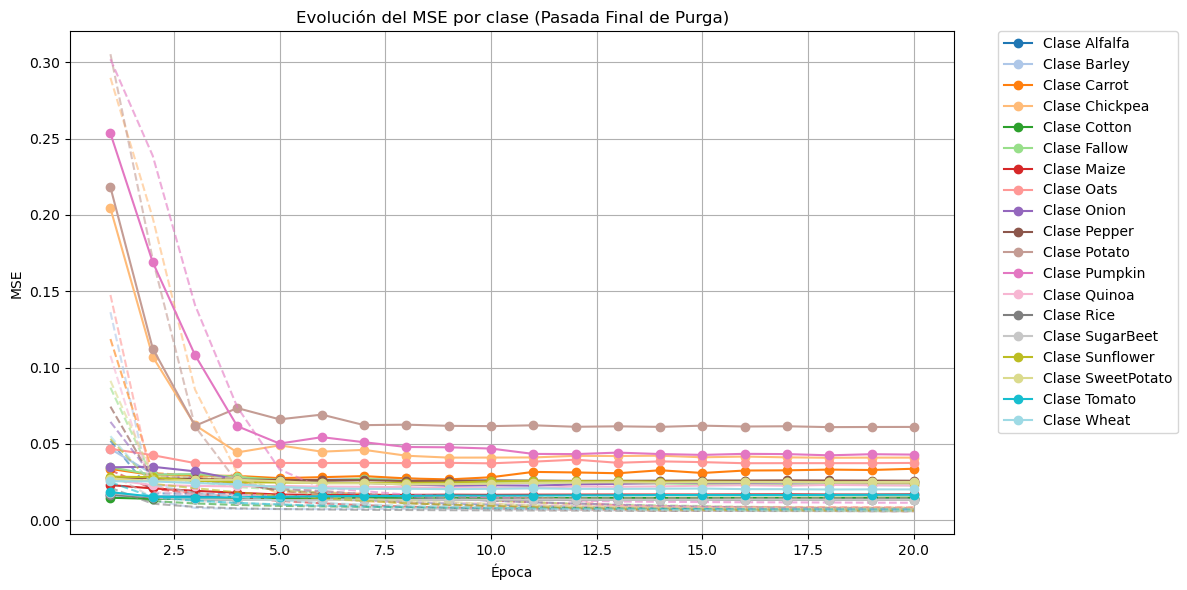

In [6]:
# ============================================================
# 1. CONFIGURACIÓN GLOBAL Y PARÁMETROS
# ============================================================
path_modelos = "/home/angelo/MyStore/Proyecto Investigador/Modelos_temporales_2019_FARMSAR+COHERENCIA_BOTTLENECK_DIM_16_10pass"
os.makedirs(path_modelos, exist_ok=True)

INPUT_CHANNELS = 4     
SEQ_LEN = 61           # 61 fechas de adquisición Sentinel-1
BOTTLENECK_DIM = 16     # Máxima compresión para detección de anomalías
EPOCHS = 20
BATCH_SIZE = 128
LR = 1e-3
NUM_PURGE_PASSES = 10  # 10 pasadas iterativas descritas en FARMSAR

val_frac = 0.15
seed_val_global = 42
device = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Utilizando dispositivo: {device}")

# ============================================================
# 2. SPLIT TRAIN/VAL FIJO A NIVEL DE PARCELA (Evita Data Leakage)
# ============================================================
datos_train = {}
datos_val = {}

for clase, datos_orig in datos_limpios.items():
    parcelas = datos_orig["parcelas"]
    if isinstance(parcelas, np.ndarray):
        parcelas = torch.tensor(parcelas)
        
    parcelas_unicas = torch.unique(parcelas)
    n_plots = len(parcelas_unicas)
    generador = torch.Generator().manual_seed(seed_val_global)
    
    n_val_plots = max(1, int(n_plots * val_frac))
    idx_perm = torch.randperm(n_plots, generator=generador)
    
    plots_train = parcelas_unicas[idx_perm[:-n_val_plots]]
    plots_val = parcelas_unicas[idx_perm[-n_val_plots:]]
    
    mask_train = torch.isin(parcelas, plots_train)
    mask_val = torch.isin(parcelas, plots_val)
    
    X_tensor = datos_orig["X"]
    if isinstance(X_tensor, np.ndarray):
        X_tensor = torch.tensor(X_tensor, dtype=torch.float32)
    if X_tensor.ndim == 2:
        X_tensor = X_tensor.view(-1, INPUT_CHANNELS, SEQ_LEN)
        
    datos_train[clase] = {
        "X": X_tensor[mask_train],
        "parcelas": parcelas[mask_train]
    }
    datos_val[clase] = {
        "X": X_tensor[mask_val],
        "parcelas": parcelas[mask_val]
    }

print(" Split Train/Val realizado a nivel de PARCELA.")

# Copia de trabajo que se irá purificando en cada iteración
X_purificado_train = {clase: datos_train[clase]["X"].clone() for clase in datos_train.keys()}

# ============================================================
# 3. BUCLE ITERATIVO DE PURGA DE FARMSAR (10 PASADAS)
# ============================================================
modelos_finales = {}
historial_global = {}

for pasada in range(1, NUM_PURGE_PASSES + 1):
    print("\n" + "=" * 60)
    print(f" PASADA DE PURGA {pasada}/{NUM_PURGE_PASSES}")
    print("=" * 60)
    
    modelos_pasada = {}
    
    # ----------------------------------------------------
    # A. Entrenar un CAE experto por cada cultivo
    # ----------------------------------------------------
    for clase in X_purificado_train.keys():
        X_tr = X_purificado_train[clase]
        X_va = datos_val[clase]["X"]
        
        print(f"\nEntrenando CAE ({clase}) - Muestras actuales: {X_tr.shape}")
        
        ruta_guardado = f"{path_modelos}/cae_pasada_{pasada}_{clase}.pth"
        
        model, mejor_loss, mejor_epoch, h_tr, h_va = entrenar_cae_por_clase(
            X_tr,
            X_va,
            Conv1DAutoencoder,
            clase,
            ruta_modelo=ruta_guardado,
            input_channels=INPUT_CHANNELS,
            seq_len=SEQ_LEN,
            bottleneck_dim=BOTTLENECK_DIM,
            batch_size=BATCH_SIZE,
            epochs=EPOCHS,
            lr=LR,
            device=device,
        )
        
        modelos_pasada[clase] = model
        
        # Guardar historial de pérdidas de la última pasada para graficar
        if pasada == NUM_PURGE_PASSES:
            historial_global[clase] = {"train": h_tr, "val": h_va, "loss": mejor_loss, "epoch": mejor_epoch}

    # ----------------------------------------------------
    # B. Evaluar píxeles y filtrar sospechosos para la siguiente pasada
    # ----------------------------------------------------
    if pasada < NUM_PURGE_PASSES:
        print("\n Evaluando reconstrucción multimodelo para purgar muestras sospechosas...")
        
        for clase in list(X_purificado_train.keys()):
            X_actual = X_purificado_train[clase]
            labels_dummy = np.array([clase] * len(X_actual))
            
            # Evaluar el conjunto actual contra TODOS los CAEs entrenados en esta pasada
            res_eval = predict_pixels(X_actual, labels_dummy, modelos_pasada, batch_size=BATCH_SIZE, device=device)
            
            # Conservar solo los píxeles confiables (donde el MSE de su propia clase fue el mínimo)
            mask_confiable = res_eval['is_trustworthy']
            num_conservados = mask_confiable.sum()
            num_eliminados = len(mask_confiable) - num_conservados
            
            # Actualizar el conjunto de entrenamiento para la siguiente pasada
            X_purificado_train[clase] = X_actual[mask_confiable]
            
            print(f"  [{clase}] Muestras retenidas: {num_conservados}/{len(mask_confiable)} | Descartadas: {num_eliminados}")

    else:
        modelos_finales = modelos_pasada

print("\n ¡Proceso de purga e iteración de 10 pasadas completado exitosamente!")

# ============================================================
# 4. GRÁFICO DE PÉRDIDAS DE LA PASADA FINAL
# ============================================================
cultivos = list(historial_global.keys())
colores = cm.tab20(np.linspace(0, 1, len(cultivos)))

plt.figure(figsize=(12, 6))
for color, clase in zip(colores, cultivos):
    plt.plot(range(1, len(historial_global[clase]["train"]) + 1), historial_global[clase]["train"],
             linestyle='--', color=color, alpha=0.6)
    plt.plot(range(1, len(historial_global[clase]["val"]) + 1), historial_global[clase]["val"],
             marker='o', color=color, label=f'Clase {clase}')

plt.xlabel("Época")
plt.ylabel("MSE")
plt.title("Evolución del MSE por clase (Pasada Final de Purga)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{path_modelos}/evolucion_perdidas_final.png", bbox_inches='tight')
plt.show()